In [1]:
import pandas as pd
import matplotlib.pyplot as plt

daten = pd.read_csv("data/bus48_modell.csv", parse_dates=["tag", "planzeit"])

# Neues Ziel: 1 = mehr als 3 Min. zu spät, 0 = pünktlich
daten["zu_spaet"] = (daten["verspaetung_min"] > 3).astype(int)

ZAHLEN = ["stunde", "wochentag", "wochenende", "schulferien", "temp", "regen_mm"]
KATEGORIEN = ["HALTESTELLEN_NAME", "richtung"]

X = pd.get_dummies(daten[ZAHLEN + KATEGORIEN], columns=KATEGORIEN, dtype=int)
y = daten["zu_spaet"]

print(f"Anteil > 3 Min. zu spät: {y.mean():.1%}")

Anteil > 3 Min. zu spät: 10.3%


In [2]:
GRENZE = pd.Timestamp("2026-10-26")
train = daten["tag"] < GRENZE
test = ~train

X_train, X_test = X[train], X[test]
y_train, y_test = y[train], y[test]
print("Training:", len(X_train), "· Test:", len(X_test))

Training: 168360 · Test: 15181


In [3]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss

# Baseline: Anteil verspäteter Busse pro Richtung und Stunde
quote = daten[train].groupby(["richtung", "stunde"])["zu_spaet"].mean()
schluessel = list(zip(daten.loc[test, "richtung"], daten.loc[test, "stunde"]))
baseline = pd.Series(schluessel, index=X_test.index).map(quote).fillna(y_train.mean())

modell = HistGradientBoostingClassifier(random_state=42)
modell.fit(X_train, y_train)
risiko = modell.predict_proba(X_test)[:, 1]   # Wahrscheinlichkeit für "zu spät"

for name, p in [("Baseline", baseline), ("Gradient Boosting", risiko)]:
    print(f"{name:20s} AUC: {roc_auc_score(y_test, p):.2f}   "
          f"Brier: {brier_score_loss(y_test, p):.3f}")

Baseline             AUC: 0.79   Brier: 0.121
Gradient Boosting    AUC: 0.81   Brier: 0.109


            vorhergesagt      echt  anzahl
stufe                                     
(0.0, 0.1]      0.044251  0.043698    8307
(0.1, 0.2]      0.144312  0.141651    2605
(0.2, 0.3]      0.251451  0.310091    1764
(0.3, 0.4]      0.345247  0.400136    1472
(0.4, 0.5]      0.432957  0.442159     778
(0.5, 1.0]      0.561769  0.552941     255


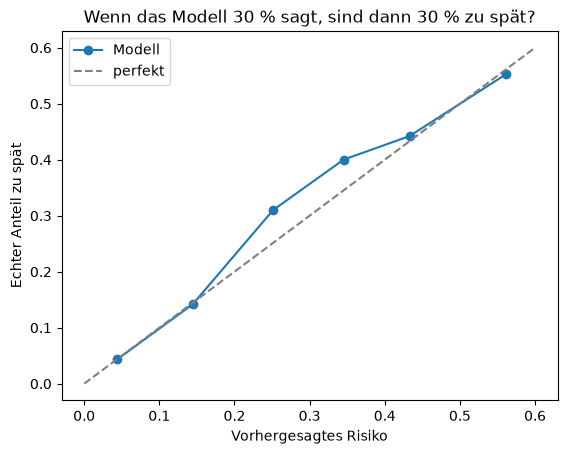

In [4]:
vergleich = pd.DataFrame({"risiko": risiko, "echt": y_test.values})
vergleich["stufe"] = pd.cut(vergleich["risiko"], bins=[0, .1, .2, .3, .4, .5, 1])
tabelle = vergleich.groupby("stufe", observed=True).agg(
    vorhergesagt=("risiko", "mean"), echt=("echt", "mean"), anzahl=("echt", "size")
)
print(tabelle)

plt.plot(tabelle["vorhergesagt"], tabelle["echt"], "o-", label="Modell")
plt.plot([0, 0.6], [0, 0.6], "--", color="grey", label="perfekt")
plt.xlabel("Vorhergesagtes Risiko")
plt.ylabel("Echter Anteil zu spät")
plt.title("Wenn das Modell 30 % sagt, sind dann 30 % zu spät?")
plt.legend()
plt.show()

In [5]:
def risiko_vorhersagen(haltestelle, richtung, stunde, wochentag, regen_mm=0.0, temp=10.0, schulferien=False):
    zeile = pd.DataFrame([{
        "stunde": stunde, "wochentag": wochentag, "wochenende": wochentag >= 5,
        "schulferien": schulferien, "temp": temp, "regen_mm": regen_mm,
        "HALTESTELLEN_NAME": haltestelle, "richtung": richtung,
    }])
    zeile = pd.get_dummies(zeile, columns=KATEGORIEN, dtype=int).reindex(columns=X.columns, fill_value=0)
    return modell.predict_proba(zeile)[0, 1]

print(f"Di 07 Uhr, Ziegelei → Stadt, trocken: {risiko_vorhersagen('Ziegelei', 'stadteinwärts', 7, 1):.0%}")
print(f"Do 17 Uhr, Ziegelei → Stadt, Regen:   {risiko_vorhersagen('Ziegelei', 'stadteinwärts', 17, 3, regen_mm=3):.0%}")

Di 07 Uhr, Ziegelei → Stadt, trocken: 8%
Do 17 Uhr, Ziegelei → Stadt, Regen:   53%
